# Nepal Earthquake Project
## Supplementary Preprocessing and Geography EDA

This notebook extends the outputs of 01_Preprocessing_EDA.ipynb. It does not modify Notebook 01 or the raw data. It loads the engineered train/test feature tables produced by Notebook 01, adds four supplementary features, performs geographic damage EDA, and saves the consolidated feature tables for modeling.

### What this notebook adds

1. `secondary_use_count`
2. `area_per_family`
3. `rc_category`
4. `age_group`
5. Geographic damage EDA for `geo_level_1_id`, `geo_level_2_id`, and `geo_level_3_id`

For convenience, this notebook also reconstructs the documented existing engineered features so that one consolidated final modeling dataset can be produced.

### Leakage rule

Geographic damage summaries use `damage_grade`, so they are **EDA outputs only**. They are never merged back into the model features.


In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
VALIDATION_SIZE = 0.20

PROJECT_DIR = Path.cwd()

# Compatible with running from either the repository root
# or the Preprocess & EDA folder.
if (PROJECT_DIR / "Preprocess & EDA").exists():
    PROJECT_DIR = PROJECT_DIR / "Preprocess & EDA"

RAW_DATA_DIR = PROJECT_DIR / "raw_data"
BASE_PROCESSED_DIR = PROJECT_DIR / "processed_data"

OUTPUT_DIR = PROJECT_DIR / "supplementary_outputs"
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
PROCESSED_DIR = PROJECT_DIR / "supplementary_processed_data"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR.resolve())
print("BASE_PROCESSED_DIR:", BASE_PROCESSED_DIR.resolve())
print("PROCESSED_DIR:", PROCESSED_DIR.resolve())


PROJECT_DIR: C:\Users\Welkin\OneDrive - HKUST Connect\Desktop\NTU_academic\semester1\6810\group_project\Preprocess & EDA
BASE_PROCESSED_DIR: C:\Users\Welkin\OneDrive - HKUST Connect\Desktop\NTU_academic\semester1\6810\group_project\Preprocess & EDA\processed_data
PROCESSED_DIR: C:\Users\Welkin\OneDrive - HKUST Connect\Desktop\NTU_academic\semester1\6810\group_project\Preprocess & EDA\supplementary_processed_data


## 1. Load the outputs from Notebook 01

Notebook 01 has already completed the core preprocessing and feature engineering.
This notebook therefore starts from its engineered feature tables and only adds
the supplementary features and geographic EDA.

In [2]:
required_base_files = [
    "train_features_engineered.csv",
    "test_features_engineered.csv",
    "train_validation_split.csv",
    "feature_metadata.json",
]

missing = [
    f for f in required_base_files
    if not (BASE_PROCESSED_DIR / f).exists()
]

if missing:
    raise FileNotFoundError(
        "Notebook 01 outputs are missing from processed_data/: "
        + ", ".join(missing)
        + "\nRun 01_Preprocessing_EDA.ipynb first."
    )

# Outputs produced by Notebook 01
train_base = pd.read_csv(
    BASE_PROCESSED_DIR / "train_features_engineered.csv"
)

test_base = pd.read_csv(
    BASE_PROCESSED_DIR / "test_features_engineered.csv"
)

split_map_base = pd.read_csv(
    BASE_PROCESSED_DIR / "train_validation_split.csv"
)

with open(
    BASE_PROCESSED_DIR / "feature_metadata.json",
    "r",
    encoding="utf-8",
) as f:
    base_feature_metadata = json.load(f)

# Labels and submission template are still read from raw_data.
train_labels = pd.read_csv(
    RAW_DATA_DIR / "train_labels.csv"
)

submission_format = pd.read_csv(
    RAW_DATA_DIR / "submission_format.csv"
)

# Integrity checks
assert train_base["building_id"].is_unique
assert test_base["building_id"].is_unique
assert train_labels["building_id"].is_unique
assert submission_format["building_id"].is_unique

assert train_base["building_id"].equals(
    train_labels["building_id"]
)

assert test_base["building_id"].equals(
    submission_format["building_id"]
)

print("Notebook 01 train features:", train_base.shape)
print("Notebook 01 test features:", test_base.shape)
print("Train labels:", train_labels.shape)
print("Existing split:", split_map_base["split"].value_counts())

Notebook 01 train features: (260601, 45)
Notebook 01 test features: (86868, 45)
Train labels: (260601, 2)
Existing split: split
train         208480
validation     52121
Name: count, dtype: int64


## 2. Reconstruct the documented existing engineered features

These features are rebuilt in this new notebook only to create a single consolidated modeling dataset.

The teammate's original files remain untouched.

Existing documented features:

* `age_is_995`
* `age_capped_100`
* `material_count`
* `height_per_floor`
* `families_per_floor`
* `has_reinforced_concrete`
* geographic IDs treated as categorical identities


In [3]:
GEO_COLS = [
    "geo_level_1_id",
    "geo_level_2_id",
    "geo_level_3_id",
]

SECONDARY_DETAIL_COLS = [
    c for c in train_base.columns
    if c.startswith("has_secondary_use_")
]

# CSV does not preserve categorical dtype.
# Restore geographic IDs as categorical identities.
for col in GEO_COLS:
    train_base[col] = train_base[col].astype(str)
    test_base[col] = test_base[col].astype(str)

print(
    "Secondary-use detail indicators:",
    len(SECONDARY_DETAIL_COLS)
)

print("Base train shape:", train_base.shape)
print("Base test shape:", test_base.shape)

Secondary-use detail indicators: 10
Base train shape: (260601, 45)
Base test shape: (86868, 45)


## 3. New feature 1: `secondary_use_count`

The raw dataset has one broad `has_secondary_use` flag plus 10 detailed secondary-use indicators.

We sum the 10 detailed indicators:

\[
secondary\_use\_count = \sum_j has\_secondary\_use_j
\]

This captures whether a building has one or several secondary uses.


In [4]:
def add_secondary_use_count(df):
    out = df.copy()
    out["secondary_use_count"] = (
        out[SECONDARY_DETAIL_COLS].sum(axis=1).astype("int8")
    )
    return out

train_s1 = add_secondary_use_count(train_base)
test_s1 = add_secondary_use_count(test_base)

# Consistency check with the broad binary flag.
train_conflict = (
    (train_s1["has_secondary_use"] == 0)
    & (train_s1["secondary_use_count"] > 0)
).sum()

test_conflict = (
    (test_s1["has_secondary_use"] == 0)
    & (test_s1["secondary_use_count"] > 0)
).sum()

print("Train broad/detail conflicts:", train_conflict)
print("Test broad/detail conflicts:", test_conflict)
display(train_s1["secondary_use_count"].value_counts().sort_index().to_frame("count"))


Train broad/detail conflicts: 0
Test broad/detail conflicts: 0


,count
secondary_use_count,
0,231445
1,28599
2,557


## 4. New feature 2: `area_per_family`

For buildings with at least one resident family:

\[
area\_per\_family
=

rac{area\_percentage}{count\_families}
\]

When `count_families = 0`, the ratio is undefined. We set it to `0` while keeping the original `count_families` feature, so the model can distinguish zero-family buildings without creating infinite values.


In [5]:
def add_area_per_family(df):
    out = df.copy()

    out["area_per_family"] = np.where(
        out["count_families"] > 0,
        out["area_percentage"] / out["count_families"],
        0.0,
    )

    return out

train_s2 = add_area_per_family(train_s1)
test_s2 = add_area_per_family(test_s1)

print(
    "Train buildings with count_families = 0:",
    int((train_s2["count_families"] == 0).sum()),
    f"({(train_s2['count_families'] == 0).mean():.2%})"
)
display(train_s2["area_per_family"].describe().to_frame().T)


Train buildings with count_families = 0: 20862 (8.01%)


,count,mean,std,min,25%,50%,75%,max
area_per_family,260601.0,7.088301,4.528453,0.0,5.0,7.0,9.0,100.0


## 5. New feature 3: `rc_category`

The existing binary `has_reinforced_concrete` is useful, but it merges engineered and non-engineered reinforced concrete.

The raw data contains both:

* `has_superstructure_rc_engineered`
* `has_superstructure_rc_non_engineered`

We retain the binary feature and add a more informative categorical feature:

* `no_rc`
* `non_engineered_rc`
* `engineered_rc`
* `mixed_rc`

`mixed_rc` is used when both RC indicators are present.


In [6]:
def add_rc_category(df):
    out = df.copy()

    engineered = out["has_superstructure_rc_engineered"].eq(1)
    non_engineered = out["has_superstructure_rc_non_engineered"].eq(1)

    out["rc_category"] = np.select(
        [
            engineered & non_engineered,
            engineered & ~non_engineered,
            ~engineered & non_engineered,
        ],
        [
            "mixed_rc",
            "engineered_rc",
            "non_engineered_rc",
        ],
        default="no_rc",
    )

    out["rc_category"] = out["rc_category"].astype("category")
    return out

train_s3 = add_rc_category(train_s2)
test_s3 = add_rc_category(test_s2)

display(train_s3["rc_category"].value_counts().to_frame("count"))


,count
rc_category,
no_rc,245464
non_engineered_rc,11004
engineered_rc,4038
mixed_rc,95


## 6. New feature 4: `age_group`

The teammate already identified `age = 995` as a special value.

To avoid mixing it into an ordinary `100+` age band, we assign it its own category.

Age groups:

* `0-10`
* `11-20`
* `21-40`
* `41-60`
* `61-100`
* `100+`
* `995_special`

The original continuous `age`, `age_is_995`, and `age_capped_100` are all retained.


In [7]:
AGE_BINS = [-1, 10, 20, 40, 60, 100, np.inf]
AGE_LABELS = ["0-10", "11-20", "21-40", "41-60", "61-100", "100+"]

def add_age_group(df):
    out = df.copy()

    ordinary_group = pd.cut(
        out["age"],
        bins=AGE_BINS,
        labels=AGE_LABELS,
    ).astype(str)

    out["age_group"] = np.where(
        out["age"] == 995,
        "995_special",
        ordinary_group,
    )

    out["age_group"] = out["age_group"].astype("category")
    return out

train_s4 = add_age_group(train_s3)
test_s4 = add_age_group(test_s3)

display(train_s4["age_group"].value_counts().sort_index().to_frame("count"))


,count
age_group,
0-10,98634
100+,734
11-20,68192
21-40,63663
41-60,17613
61-100,10375
995_special,1390


## 7. Geography damage EDA

This section uses `damage_grade` only for descriptive analysis.

It produces:

* damage summary for geo levels 1, 2, and 3
* Grade-3 damage rate by `geo_level_1_id`
* top and bottom Level-1 regions by severe-damage rate

These target-based statistics are **not used as model features**.


In [8]:
eda_train = train_s4.merge(
    train_labels,
    on="building_id",
    how="inner",
    validate="one_to_one",
)

def geographic_damage_summary(df, geo_col):
    return (
        df.groupby(geo_col, observed=True)
        .agg(
            n_buildings=("damage_grade", "size"),
            mean_damage_grade=("damage_grade", "mean"),
            grade1_rate=("damage_grade", lambda s: (s == 1).mean()),
            grade2_rate=("damage_grade", lambda s: (s == 2).mean()),
            grade3_rate=("damage_grade", lambda s: (s == 3).mean()),
        )
        .sort_values("grade3_rate", ascending=False)
    )

geo_summaries = {}

for col in GEO_COLS:
    summary = geographic_damage_summary(eda_train, col)
    geo_summaries[col] = summary
    summary.to_csv(TABLE_DIR / f"{col}_damage_summary.csv")

geo1 = geo_summaries["geo_level_1_id"]

print("Geo Level 1 Grade-3 rate range:")
print("min:", f"{geo1['grade3_rate'].min():.2%}")
print("max:", f"{geo1['grade3_rate'].max():.2%}")

print("\nHighest Grade-3 Level-1 regions:")
display(geo1.head(10))

print("Lowest Grade-3 Level-1 regions:")
display(geo1.sort_values("grade3_rate").head(10))


Geo Level 1 Grade-3 rate range:
min: 8.55%
max: 80.75%

Highest Grade-3 Level-1 regions:


,n_buildings,mean_damage_grade,grade1_rate,grade2_rate,grade3_rate
geo_level_1_id,,,,,
17,21813,2.794480,0.013066,0.179388,0.807546
18,3189,2.708373,0.022578,0.246472,0.730950
21,14889,2.563369,0.021627,0.393378,0.584996
8,19080,2.485273,0.034277,0.446174,0.519549
27,12532,2.446457,0.037105,0.479333,0.483562
28,265,2.407547,0.000000,0.592453,0.407547
10,22079,2.341954,0.054848,0.548349,0.396802
11,8220,2.337713,0.046959,0.568370,0.384672
3,7540,2.331565,0.032493,0.603448,0.364058


Lowest Grade-3 Level-1 regions:


,n_buildings,mean_damage_grade,grade1_rate,grade2_rate,grade3_rate
geo_level_1_id,,,,,
5,2690,1.919703,0.165799,0.748699,0.085502
26,22615,1.730887,0.354986,0.559142,0.085872
29,396,2.078283,0.020202,0.881313,0.098485
24,1310,1.894656,0.206107,0.693130,0.100763
1,2701,1.960755,0.152166,0.734913,0.112921
30,2686,2.020477,0.093820,0.791884,0.114296
20,17216,1.926464,0.192321,0.688894,0.118785
22,6252,2.000960,0.129718,0.739603,0.130678
25,5624,2.054054,0.083215,0.779516,0.137269


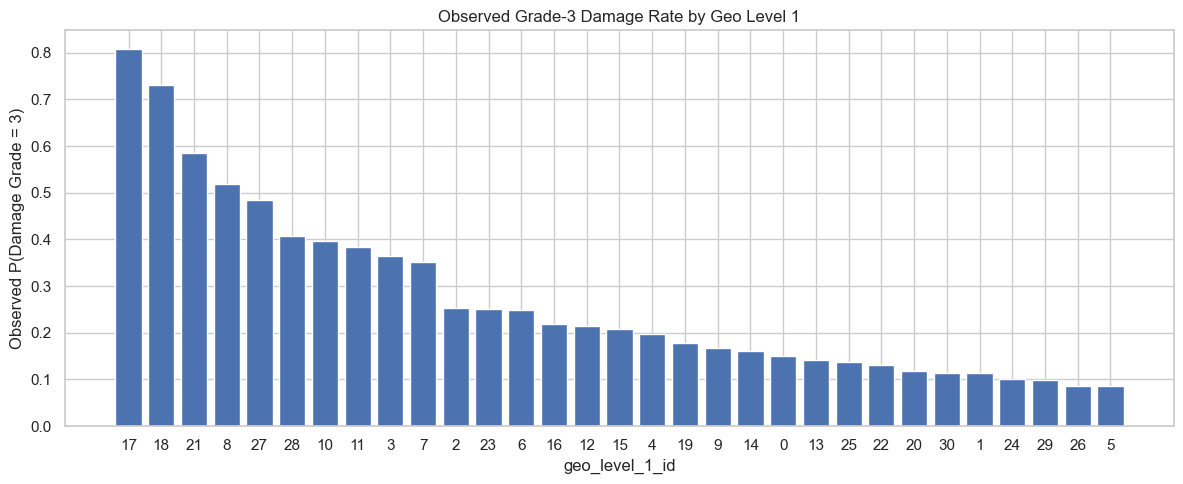

Saved: c:\Users\Welkin\OneDrive - HKUST Connect\Desktop\NTU_academic\semester1\6810\group_project\Preprocess & EDA\supplementary_outputs\figures\geo_level_1_grade3_rate.png


In [9]:
geo1_plot = geo1.sort_values("grade3_rate", ascending=False)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(
    geo1_plot.index.astype(str),
    geo1_plot["grade3_rate"],
)
ax.set_title("Observed Grade-3 Damage Rate by Geo Level 1")
ax.set_xlabel("geo_level_1_id")
ax.set_ylabel("Observed P(Damage Grade = 3)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()

geo_fig_path = FIG_DIR / "geo_level_1_grade3_rate.png"
fig.savefig(geo_fig_path, dpi=220, bbox_inches="tight")
plt.show()

print("Saved:", geo_fig_path)


## 8. Assemble the complete feature files

The final dataset contains:

1. all original official features
2. the teammate's documented engineered features
3. the four new model features in this supplement

The geography EDA summaries stay separate because they use the target.


In [10]:
final_train_features = train_s4.copy()
final_test_features = test_s4.copy()

assert final_train_features["building_id"].equals(
    train_base["building_id"]
)

assert final_test_features["building_id"].equals(
    test_base["building_id"]
)

assert (
    list(final_train_features.columns)
    == list(final_test_features.columns)
)

new_features = [
    "secondary_use_count",
    "area_per_family",
    "rc_category",
    "age_group",
]

print(
    "Final train feature table:",
    final_train_features.shape
)

print(
    "Final test feature table:",
    final_test_features.shape
)

print(
    "New supplement model features:",
    new_features
)

Final train feature table: (260601, 49)
Final test feature table: (86868, 49)
New supplement model features: ['secondary_use_count', 'area_per_family', 'rc_category', 'age_group']


## 9. Save final processed data without overwriting teammate files

We save both CSV and pickle versions.

The pickle files preserve pandas categorical dtypes. CSV files are convenient for inspection, but when reloaded, geographic IDs may be inferred as integers again. The schema JSON records which columns must be treated as categorical during modeling.


In [11]:
# CSV outputs for portability
final_train_features.to_csv(
    PROCESSED_DIR / "train_features_complete.csv",
    index=False,
)
final_test_features.to_csv(
    PROCESSED_DIR / "test_features_complete.csv",
    index=False,
)
train_labels.to_csv(
    PROCESSED_DIR / "train_labels.csv",
    index=False,
)
submission_format.to_csv(
    PROCESSED_DIR / "submission_format.csv",
    index=False,
)

# Pickle outputs preserve category dtype and strings.
final_train_features.to_pickle(
    PROCESSED_DIR / "train_features_complete.pkl"
)
final_test_features.to_pickle(
    PROCESSED_DIR / "test_features_complete.pkl"
)


base_categorical_cols = [
    c for c in train_base.columns
    if train_base[c].dtype == "object"
]

categorical_cols = sorted(
    set(
        base_categorical_cols
        + GEO_COLS
        + ["rc_category", "age_group"]
    )
)

categorical_cols = sorted(
    set(
        base_categorical_cols
        + GEO_COLS
        + ["rc_category", "age_group"]
    )
)

schema = {
    "building_id": "identifier_only_drop_before_model_fit",
    "target": "damage_grade",
    "categorical_columns": categorical_cols,
    "new_supplement_features": new_features,
    "features_inherited_from_notebook_01": [
        "age_is_995",
        "age_capped_100",
        "material_count",
        "height_per_floor",
        "families_per_floor",
        "has_reinforced_concrete",
    ],
    "geography_eda_target_statistics_are_model_features": False,
}

with open(
    PROCESSED_DIR / "feature_schema.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(schema, f, indent=2)

print("Saved complete train/test feature files and feature_schema.json")


Saved complete train/test feature files and feature_schema.json


## 10. Preserve the train-validation split from Notebook 01

Notebook 02 does not create a new split. It preserves the exact building-level
train-validation assignment created by Notebook 01 so that all later modeling
experiments use the same validation set.

In [12]:
split_map = split_map_base.copy()

assert set(split_map["building_id"]) == set(
    train_labels["building_id"]
)

split_map.to_csv(
    PROCESSED_DIR / "train_validation_split_complete.csv",
    index=False,
)

print(split_map["split"].value_counts())

split_check = (
    train_labels
    .merge(
        split_map,
        on="building_id",
        how="inner",
        validate="one_to_one",
    )
    .groupby("split")["damage_grade"]
    .value_counts(normalize=True)
    .rename("proportion")
    .reset_index()
)

display(split_check)

split
train         208480
validation     52121
Name: count, dtype: int64


,split,damage_grade,proportion
0,train,2,0.568913
1,train,3,0.334680
2,train,1,0.096407
3,validation,2,0.568907
4,validation,3,0.334683
5,validation,1,0.096410


## 11. Final handoff summary

### Additional model features created here

* `secondary_use_count`
* `area_per_family`
* `rc_category`
* `age_group`

### Additional EDA created here

* Level-1, Level-2, and Level-3 geographic damage summary tables
* Level-1 severe-damage rate chart

### Important modeling notes

1. Drop `building_id` before fitting models.
2. Treat all columns listed in `feature_schema.json` as categorical when required by the model.
3. CatBoost can use the categorical features directly.
4. Geographic damage summary tables are descriptive EDA only.
5. Do not merge observed `damage_grade` rates back into the feature matrix unless a fully out-of-fold target-encoding procedure is implemented later.


## 12. Before training: check whether the date for training is correctly generated

In [13]:
from pathlib import Path
import json
import pandas as pd
import numpy as np

# =========================================================
# 0. Locate project folders
# =========================================================

PROJECT_DIR = Path.cwd()

if (PROJECT_DIR / "Preprocess & EDA").exists():
    PROJECT_DIR = PROJECT_DIR / "Preprocess & EDA"

BASE_DIR = PROJECT_DIR / "processed_data"
SUPP_DIR = PROJECT_DIR / "supplementary_processed_data"
RAW_DIR = PROJECT_DIR / "raw_data"

print("PROJECT_DIR:", PROJECT_DIR.resolve())


# =========================================================
# 1. Check required files exist
# =========================================================

required_01 = [
    "train_features_engineered.csv",
    "test_features_engineered.csv",
    "train_validation_split.csv",
    "feature_metadata.json",
]

required_02 = [
    "train_features_complete.csv",
    "test_features_complete.csv",
    "train_features_complete.pkl",
    "test_features_complete.pkl",
    "train_validation_split_complete.csv",
    "feature_schema.json",
]

required_raw = [
    "train_labels.csv",
    "submission_format.csv",
]

for f in required_01:
    assert (BASE_DIR / f).exists(), f"Missing 01 output: {f}"

for f in required_02:
    assert (SUPP_DIR / f).exists(), f"Missing 02 output: {f}"

for f in required_raw:
    assert (RAW_DIR / f).exists(), f"Missing raw file: {f}"

print("✓ All required files exist")


# =========================================================
# 2. Load data
# =========================================================

base_train = pd.read_csv(
    BASE_DIR / "train_features_engineered.csv"
)

base_test = pd.read_csv(
    BASE_DIR / "test_features_engineered.csv"
)

final_train = pd.read_pickle(
    SUPP_DIR / "train_features_complete.pkl"
)

final_test = pd.read_pickle(
    SUPP_DIR / "test_features_complete.pkl"
)

labels = pd.read_csv(
    RAW_DIR / "train_labels.csv"
)

submission = pd.read_csv(
    RAW_DIR / "submission_format.csv"
)

split_01 = pd.read_csv(
    BASE_DIR / "train_validation_split.csv"
)

split_02 = pd.read_csv(
    SUPP_DIR / "train_validation_split_complete.csv"
)

with open(
    SUPP_DIR / "feature_schema.json",
    "r",
    encoding="utf-8"
) as f:
    schema = json.load(f)


# =========================================================
# 3. Expected dimensions
# =========================================================

print("\n--- Shapes ---")
print("01 train:", base_train.shape)
print("01 test :", base_test.shape)
print("02 train:", final_train.shape)
print("02 test :", final_test.shape)

assert base_train.shape == (260601, 45), \
    f"Unexpected 01 train shape: {base_train.shape}"

assert base_test.shape == (86868, 45), \
    f"Unexpected 01 test shape: {base_test.shape}"

assert final_train.shape == (260601, 49), \
    f"Unexpected 02 train shape: {final_train.shape}"

assert final_test.shape == (86868, 49), \
    f"Unexpected 02 test shape: {final_test.shape}"

print("✓ Shapes are correct")


# =========================================================
# 4. Train / test feature schema must match
# =========================================================

assert list(final_train.columns) == list(final_test.columns), \
    "Train and test feature columns do not match"

print("✓ Train/test feature columns match")


# =========================================================
# 5. Building IDs
# =========================================================

assert final_train["building_id"].is_unique
assert final_test["building_id"].is_unique

assert final_train["building_id"].equals(labels["building_id"]), \
    "Train features and labels are misaligned"

assert final_test["building_id"].equals(submission["building_id"]), \
    "Test features and submission IDs are misaligned"

print("✓ building_id alignment is correct")


# =========================================================
# 6. Check supplementary features were really added
# =========================================================

supplementary_features = [
    "secondary_use_count",
    "area_per_family",
    "rc_category",
    "age_group",
]

for col in supplementary_features:
    assert col in final_train.columns, \
        f"Missing supplementary feature: {col}"

print("✓ All 4 supplementary features exist")


# =========================================================
# 7. Check all 01 features survived into 02
# =========================================================

base_columns = set(base_train.columns)
final_columns = set(final_train.columns)

missing_from_02 = base_columns - final_columns

assert len(missing_from_02) == 0, \
    f"02 lost features from 01: {missing_from_02}"

print("✓ All Notebook 01 features are preserved in Notebook 02")


# =========================================================
# 8. No target leakage
# =========================================================

assert "damage_grade" not in final_train.columns, \
    "TARGET LEAKAGE: damage_grade appears in training features"

assert "damage_grade" not in final_test.columns, \
    "damage_grade unexpectedly appears in test features"

print("✓ No damage_grade target leakage")


# =========================================================
# 9. Missing and infinite values
# =========================================================

missing_train = final_train.isna().sum().sum()
missing_test = final_test.isna().sum().sum()

print("\nMissing cells:")
print("train:", missing_train)
print("test :", missing_test)

assert missing_train == 0, \
    f"Train contains {missing_train} missing cells"

assert missing_test == 0, \
    f"Test contains {missing_test} missing cells"

numeric_train = final_train.select_dtypes(include=np.number)
numeric_test = final_test.select_dtypes(include=np.number)

assert np.isfinite(numeric_train.to_numpy()).all(), \
    "Train contains inf/-inf"

assert np.isfinite(numeric_test.to_numpy()).all(), \
    "Test contains inf/-inf"

print("✓ No missing or infinite values")


# =========================================================
# 10. Check categorical variables
# =========================================================

geo_cols = [
    "geo_level_1_id",
    "geo_level_2_id",
    "geo_level_3_id",
]

for col in geo_cols:
    assert (
        pd.api.types.is_object_dtype(final_train[col])
        or isinstance(final_train[col].dtype, pd.CategoricalDtype)
    ), f"{col} is not categorical/string in final pickle"

for col in ["rc_category", "age_group"]:
    assert (
        pd.api.types.is_object_dtype(final_train[col])
        or isinstance(final_train[col].dtype, pd.CategoricalDtype)
    ), f"{col} is not categorical"

print("✓ Important categorical features have correct dtype")


# =========================================================
# 11. Schema metadata
# =========================================================

expected_schema_cats = set(
    geo_cols + ["rc_category", "age_group"]
)

schema_cats = set(schema["categorical_columns"])

assert expected_schema_cats.issubset(schema_cats), \
    "feature_schema.json is missing required categorical columns"

print("✓ feature_schema.json is consistent")


# =========================================================
# 12. Split validation
# =========================================================

print("\n--- Split counts ---")
print(split_02["split"].value_counts())

assert len(split_02) == 260601
assert split_02["building_id"].is_unique

assert set(split_02["split"].unique()) == {
    "train",
    "validation"
}

assert (split_02["split"] == "train").sum() == 208480
assert (split_02["split"] == "validation").sum() == 52121

print("✓ Split size is correct")


# =========================================================
# 13. Confirm 01 and 02 use EXACTLY the same split
# =========================================================

compare_split = (
    split_01[["building_id", "split"]]
    .merge(
        split_02[["building_id", "split"]],
        on="building_id",
        suffixes=("_01", "_02"),
        validate="one_to_one",
    )
)

same_split = (
    compare_split["split_01"]
    == compare_split["split_02"]
).all()

assert same_split, \
    "01 and 02 train/validation assignments are different"

print("✓ Notebook 01 and 02 use exactly the same split")


# =========================================================
# 14. Verify class proportions
# =========================================================

split_with_labels = labels.merge(
    split_02,
    on="building_id",
    validate="one_to_one",
)

class_distribution = (
    split_with_labels
    .groupby("split")["damage_grade"]
    .value_counts(normalize=True)
    .unstack()
)

print("\n--- Class distribution by split ---")
display(class_distribution)

global_distribution = (
    labels["damage_grade"]
    .value_counts(normalize=True)
    .sort_index()
)

print("\nOverall distribution:")
display(global_distribution)

print("✓ Stratification can be visually confirmed above")


# =========================================================
# 15. Final modeling feature count
# =========================================================

model_features = [
    c for c in final_train.columns
    if c != "building_id"
]

assert len(model_features) == 48, \
    f"Expected 48 modeling features, got {len(model_features)}"

print("\nNumber of usable modeling features:", len(model_features))


# =========================================================
# FINAL
# =========================================================

print("\n" + "=" * 65)
print("ALL PREPROCESSING CHECKS PASSED")
print("DATA IS READY FOR 03 MODEL TRAINING")
print("=" * 65)

PROJECT_DIR: C:\Users\Welkin\OneDrive - HKUST Connect\Desktop\NTU_academic\semester1\6810\group_project\Preprocess & EDA
✓ All required files exist

--- Shapes ---
01 train: (260601, 45)
01 test : (86868, 45)
02 train: (260601, 49)
02 test : (86868, 49)
✓ Shapes are correct
✓ Train/test feature columns match
✓ building_id alignment is correct
✓ All 4 supplementary features exist
✓ All Notebook 01 features are preserved in Notebook 02
✓ No damage_grade target leakage

Missing cells:
train: 0
test : 0
✓ No missing or infinite values
✓ Important categorical features have correct dtype
✓ feature_schema.json is consistent

--- Split counts ---
split
train         208480
validation     52121
Name: count, dtype: int64
✓ Split size is correct
✓ Notebook 01 and 02 use exactly the same split

--- Class distribution by split ---


damage_grade,1,2,3
split,,,
train,0.096407,0.568913,0.334680
validation,0.096410,0.568907,0.334683



Overall distribution:


damage_grade
1    0.096408
2    0.568912
3    0.334680
Name: proportion, dtype: float64

✓ Stratification can be visually confirmed above

Number of usable modeling features: 48

ALL PREPROCESSING CHECKS PASSED
DATA IS READY FOR 03 MODEL TRAINING
